# FL-BENCH-004.10 — Natural multi-site benchmark: UCI heart disease (4 collection sites as clients)

*Epic EPIC-001 · story fl_bench_004 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Replace synthetic client partitions by NATURAL site heterogeneity (Cleveland, Hungary, Switzerland, VA Long Beach), with within-site and leave-one-site-out protocols, nested tuning, pooled/local baselines and a secure-aggregation equivalence check.

## 2. Scientific background
Real federations differ by site in prevalence, measurement practice and missingness [kairouz2021, rieke2020]; benchmark rankings depend on how heterogeneity is created [hsu2019, li2021niid]. Data: UCI Heart Disease [uci_heart], four site files fetched from a commit-pinned mirror and hash-verified.

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Do the algorithm rankings from synthetic partitions hold when the clients are natural cohorts?
- **RQ2.** How well does a model trained on three sites transfer to the fourth (external validation)?
- **RQ3.** Does federated training beat local-only training and approach pooled training?

## 4. Hypotheses
- **H1.** Differences between FL algorithms are within noise at n=920 with four clients.
- **H2.** Transfer to Switzerland (positive rate 0.93, cholesterol missing) is clearly worse than to Cleveland in balanced accuracy.

## 5. Mathematical formulation
Protocol A: per site 70/30 stratified; 4 clients = 4 sites; nested tuning on 25% validation per split; 10 splits. Protocol B: train on 3 sites, test on all rows of the 4th; tuned on 25% validation of the training sites; 10 initialisation seeds (data fixed). Balanced accuracy = (recall + specificity)/2.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_bench_004"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_bench_004


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
print("No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.")
print(json.dumps(json.load(open(next(RES.glob("*.json"))))["provenance"]["config"], indent=1)[:800])

No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.
{
 "search_space": {
  "lr": "log-uniform [0.005, 0.8]",
  "mu": "log-uniform [1e-3, 1] (FedProx)",
  "batch_size": [
   16,
   32,
   64
  ],
  "local_epochs": [
   1,
   2,
   3,
   5
  ],
  "hidden": [
   16,
   32,
   64
  ],
  "server_lr": "[0.5, 1, 1.5] (SCAFFOLD)"
 },
 "n_random_configs": 24,
 "grid_configs": {
  "fedavg_like": 7,
  "fedprox": 42
 },
 "rounds": 30,
 "tune_seeds": [
  100,
  101
 ],
 "eval_seeds": [
  0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9
 ],
 "natural_site_splits": [
  0,
  1,
  2,
  3,
  4
 ],
 "selection": "mean validation F1 on 25% of TRAIN; test untouched",
 "compute_note": "local_epochs and hidden width change per-round compute, so budgets are matched in number of configurations, NOT in FLOPs"
}


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`real_sites.py`, `experiments/ext2.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.preprocessing.multisite_heart import load_sites, load_loso, SITE_NAMES
try:
    sd = load_sites(SEED); print("train sizes per site:", sd.meta["site_train_sizes"], "| positive rate per site:", [round(x, 2) for x in sd.meta["site_positive_rate"]])
    lo = load_loso("switzerland"); print("LOSO Switzerland: train sites", lo.site_names, "| test rows", len(lo.y_test), "| test positive rate", round(float(lo.y_test.mean()), 2))
    assert len(sd.parts) == 4 and lo.X_test.shape[0] == 123
except Exception as e:  # needs network (GitHub) or data/raw/ on first use; stored results below do not
    print("live check skipped (data files not reachable):", type(e).__name__, str(e)[:120])

train sizes per site: [212, 205, 86, 140] | positive rate per site: [0.46, 0.36, 0.93, 0.74]
LOSO Switzerland: train sites ('cleveland', 'hungary', 'va_long_beach') | test rows 123 | test positive rate 0.93


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-BENCH-004.10` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_4_10_A_runs.csv')
show_csv('task_4_10_A_site_metrics.csv')
show_csv('task_4_10_A_tuned_params.csv')
show_csv('task_4_10_A_baselines.csv')
show_csv('task_4_10_B_runs.csv')
show_csv('task_4_10_B_tuned_params.csv')
show_csv('task_4_10_B_baselines.csv')
show_csv('task_4_10_secagg_equivalence.csv')

,split,algo,setting,lr,mu,acc,f1,auc,loss,recall,specificity,bacc
0,0,fedavg,default,0.05,0.05,0.8014,0.8232,0.8558,0.4833,0.8312,0.7642,0.7977
1,0,fedavg,tuned,0.10,0.00,0.8014,0.8232,0.8570,0.4830,0.8312,0.7642,0.7977
2,0,fedprox,default,0.05,0.05,0.8014,0.8232,0.8557,0.4831,0.8312,0.7642,0.7977
3,0,fedprox,tuned,0.80,1.00,0.7834,0.8125,0.8482,0.4964,0.8442,0.7073,0.7757
4,0,scaffold,default,0.05,0.05,0.8051,0.8323,0.8517,0.4864,0.8701,0.7236,0.7969
5,0,scaffold,tuned,0.03,0.00,0.7978,0.8261,0.8509,0.4850,0.8636,0.7154,0.7895
6,0,fednova,default,0.05,0.05,0.7942,0.8213,0.8549,0.4815,0.8506,0.7236,0.7871
7,0,fednova,tuned,0.10,0.00,0.8051,0.8333,0.8569,0.4812,0.8766,0.7154,0.7960
8,1,fedavg,default,0.05,0.05,0.7653,0.7869,0.8379,0.5186,0.7792,0.7480,0.7636
9,1,fedavg,tuned,0.10,0.00,0.7653,0.7855,0.8369,0.5239,0.7727,0.7561,0.7644


,split,algo,site,n_test,acc,f1,auc
0,0,fedavg,cleveland,91,0.8242,0.8049,0.8824
1,0,fedavg,hungary,89,0.7865,0.7246,0.8405
2,0,fedavg,switzerland,37,0.8919,0.9394,0.9429
3,0,fedavg,va_long_beach,60,0.7333,0.8298,0.7037
4,0,fedprox,cleveland,91,0.8022,0.7907,0.8639
5,0,fedprox,hungary,89,0.7528,0.7027,0.8366
6,0,fedprox,switzerland,37,0.8649,0.9231,0.9286
7,0,fedprox,va_long_beach,60,0.7500,0.8421,0.6933
8,0,scaffold,cleveland,91,0.8242,0.8095,0.8776
9,0,scaffold,hungary,89,0.7640,0.7123,0.8295


,split,algo,lr,mu
0,0,fedavg,0.10,0.0
1,0,fedprox,0.80,1.0
2,0,scaffold,0.03,0.0
3,0,fednova,0.10,0.0
4,1,fedavg,0.10,0.0
5,1,fedprox,0.10,1.0
6,1,scaffold,0.05,0.0
7,1,fednova,0.05,0.0
8,2,fedavg,0.20,0.0
9,2,fedprox,0.40,0.5


,split,method,acc,f1,auc,bacc
0,0,centralized(pooled),0.8051,0.8302,0.8559,0.7985
1,0,"local-only(mean of 4 site models, pooled test)",0.7139,0.7676,0.8122,0.6995
2,1,centralized(pooled),0.7726,0.7987,0.8397,0.7676
3,1,"local-only(mean of 4 site models, pooled test)",0.6823,0.7386,0.8143,0.6658
4,2,centralized(pooled),0.7978,0.8194,0.8691,0.7945
5,2,"local-only(mean of 4 site models, pooled test)",0.7013,0.7519,0.8062,0.6888
6,3,centralized(pooled),0.8014,0.8318,0.8940,0.7912
7,3,"local-only(mean of 4 site models, pooled test)",0.7166,0.7687,0.8314,0.7026
8,4,centralized(pooled),0.7762,0.8075,0.8466,0.7676
9,4,"local-only(mean of 4 site models, pooled test)",0.7121,0.7710,0.8197,0.6948


,held_out,seed,algo,setting,acc,f1,auc,loss,recall,specificity,bacc
0,cleveland,0,fedavg,default,0.7492,0.7450,0.8476,0.4919,0.7986,0.7073,0.7529
1,cleveland,1,fedavg,default,0.7492,0.7379,0.8448,0.4936,0.7698,0.7317,0.7507
2,cleveland,2,fedavg,default,0.7492,0.7516,0.8519,0.4948,0.8273,0.6829,0.7551
3,cleveland,3,fedavg,default,0.7459,0.7425,0.8469,0.4957,0.7986,0.7012,0.7499
4,cleveland,4,fedavg,default,0.7624,0.7632,0.8593,0.4804,0.8345,0.7012,0.7679
5,cleveland,5,fedavg,default,0.7393,0.7410,0.8455,0.4994,0.8129,0.6768,0.7449
6,cleveland,6,fedavg,default,0.7459,0.7442,0.8598,0.4829,0.8058,0.6951,0.7504
7,cleveland,7,fedavg,default,0.7327,0.7362,0.8338,0.5159,0.8129,0.6646,0.7388
8,cleveland,8,fedavg,default,0.7558,0.7517,0.8458,0.4952,0.8058,0.7134,0.7596
9,cleveland,9,fedavg,default,0.7525,0.7475,0.8559,0.4792,0.7986,0.7134,0.7560


,held_out,algo,lr,mu
0,cleveland,fedavg,0.01,0.0
1,cleveland,fedprox,0.20,1.0
2,cleveland,scaffold,0.03,0.0
3,cleveland,fednova,0.01,0.0
4,hungary,fedavg,0.05,0.0
5,hungary,fedprox,0.05,0.5
6,hungary,scaffold,0.03,0.0
7,hungary,fednova,0.05,0.0
8,switzerland,fedavg,0.03,0.0
9,switzerland,fedprox,0.05,1.0


,held_out,seed,method,acc,f1,auc,bacc
0,cleveland,0,centralized(pooled 3 sites),0.7393,0.7460,0.8513,0.7465
1,cleveland,1,centralized(pooled 3 sites),0.7459,0.7442,0.8427,0.7504
2,cleveland,2,centralized(pooled 3 sites),0.7360,0.7531,0.8486,0.7468
3,cleveland,3,centralized(pooled 3 sites),0.7657,0.7657,0.8439,0.7709
4,cleveland,4,centralized(pooled 3 sites),0.7492,0.7564,0.8580,0.7568
5,cleveland,5,centralized(pooled 3 sites),0.7459,0.7475,0.8400,0.7515
6,cleveland,6,centralized(pooled 3 sites),0.7657,0.7577,0.8619,0.7682
7,cleveland,7,centralized(pooled 3 sites),0.7525,0.7619,0.8358,0.7609
8,cleveland,8,centralized(pooled 3 sites),0.7591,0.7559,0.8455,0.7632
9,cleveland,9,centralized(pooled 3 sites),0.7393,0.7427,0.8558,0.7454


,split,max_abs_param_diff_secagg_vs_plain,f1_plain,f1_secagg
0,0,0.0,0.8232,0.8232
1,1,0.0,0.7855,0.7855
2,2,0.0,0.7907,0.7907


## 12. Metrics collection
Metric definitions: test acc/F1/AUC/balanced accuracy (pooled and per site for A; held-out site for B); pooled and local-only baselines.

In [8]:
show_csv('task_4_10_A_summary.csv', 12); show_csv('task_4_10_A_baselines_summary.csv'); show_csv('task_4_10_B_macro.csv', 12)

,algo,setting,n,acc,acc_ci,f1,f1_ci,auc,auc_ci,bacc,bacc_ci
0,fedavg,default,10,0.7852,"[0.7732, 0.7972]",0.8060,"[0.7950, 0.8170]",0.8592,"[0.8468, 0.8715]",0.7830,"[0.7708, 0.7952]"
1,fedavg,tuned,10,0.7773,"[0.7646, 0.7899]",0.7993,"[0.7877, 0.8108]",0.8531,"[0.8427, 0.8636]",0.7746,"[0.7616, 0.7877]"
2,fedprox,default,10,0.7852,"[0.7732, 0.7972]",0.8060,"[0.7950, 0.8170]",0.8591,"[0.8468, 0.8715]",0.7830,"[0.7708, 0.7952]"
3,fedprox,tuned,10,0.7776,"[0.7657, 0.7896]",0.8008,"[0.7907, 0.8109]",0.8537,"[0.8418, 0.8656]",0.7743,"[0.7612, 0.7874]"
4,scaffold,default,10,0.7968,"[0.7870, 0.8065]",0.8242,"[0.8163, 0.8322]",0.8576,"[0.8448, 0.8704]",0.7891,"[0.7787, 0.7996]"
5,scaffold,tuned,10,0.7892,"[0.7774, 0.8009]",0.8147,"[0.8023, 0.8271]",0.8471,"[0.8368, 0.8575]",0.7834,"[0.7723, 0.7944]"
6,fednova,default,10,0.7917,"[0.7801, 0.8032]",0.8167,"[0.8061, 0.8273]",0.8598,"[0.8474, 0.8723]",0.7862,"[0.7745, 0.7980]"
7,fednova,tuned,10,0.7877,"[0.7727, 0.8027]",0.8141,"[0.7987, 0.8294]",0.8545,"[0.8413, 0.8677]",0.7814,"[0.7672, 0.7957]"


,method,n,acc,acc_ci,f1,f1_ci,auc,auc_ci,bacc,bacc_ci
0,centralized(pooled),10,0.7888,"[0.7795, 0.7981]",0.8135,"[0.8047, 0.8224]",0.8596,"[0.8477, 0.8715]",0.7837,"[0.7743, 0.7931]"
1,"local-only(mean of 4 site models, pooled test)",10,0.7044,"[0.6974, 0.7115]",0.7594,"[0.7525, 0.7664]",0.8173,"[0.8112, 0.8235]",0.6893,"[0.6817, 0.6969]"


,algo,setting,acc,f1,auc,bacc
0,fedavg,default,0.7537,0.7882,0.7943,0.7202
1,fedavg,tuned,0.7546,0.7879,0.8003,0.7237
2,fedprox,default,0.7539,0.7885,0.7944,0.7207
3,fedprox,tuned,0.7515,0.7880,0.7948,0.7191
4,scaffold,default,0.7500,0.7924,0.7897,0.7145
5,scaffold,tuned,0.7490,0.7923,0.7914,0.7145
6,fednova,default,0.7516,0.7918,0.7927,0.7162
7,fednova,tuned,0.7540,0.7933,0.7960,0.7189


## 13. Statistical analysis
Protocol A: paired tuned-vs-default tests by split, Friedman + Holm across algorithms. Protocol B: seeds replicate only initialisation (data fixed) and only four sites exist, so results are descriptive; a Friedman test over the four site means is shown with that caveat.

In [9]:
show_csv('task_4_10_A_tuned_vs_default_tests.csv'); show_csv('task_4_10_A_pairwise.csv'); show_csv('task_4_10_B_summary.csv', 40)

,n,mean_diff,dz,wilcoxon_p,ttest_p,algo,metric,note
0,10,-0.0067,-0.4976,0.1484,0.1501,fedavg,f1,"tuned - default, paired by split"
1,10,-0.0052,-0.5347,0.2754,0.1251,fedprox,f1,"tuned - default, paired by split"
2,10,-0.0096,-0.5957,0.0977,0.0922,scaffold,f1,"tuned - default, paired by split"
3,10,-0.0026,-0.2330,0.6406,0.4799,fednova,f1,"tuned - default, paired by split"


,n,mean_diff,dz,wilcoxon_p,ttest_p,a,b,holm_p
0,10,-0.0015,-0.1117,0.8438,0.7321,fedavg,fedprox,1.0000
1,10,-0.0154,-0.6701,0.0645,0.0631,fedavg,scaffold,0.3223
2,10,-0.0148,-0.6924,0.0645,0.0563,fedavg,fednova,0.3223
3,10,-0.0139,-0.5375,0.1309,0.1234,fedprox,scaffold,0.3926
4,10,-0.0133,-0.8169,0.0273,0.0295,fedprox,fednova,0.1641
5,10,0.0006,0.0255,0.9219,0.9375,scaffold,fednova,1.0000


,held_out,algo,setting,n,acc,acc_ci,f1,f1_ci,auc,auc_ci,bacc,bacc_ci
0,cleveland,fedavg,default,10,0.7482,"[0.7423, 0.7541]",0.7461,"[0.7404, 0.7517]",0.8491,"[0.8435, 0.8548]",0.7526,"[0.7470, 0.7583]"
1,cleveland,fedavg,tuned,10,0.7663,"[0.7576, 0.7751]",0.7568,"[0.7474, 0.7662]",0.8654,"[0.8611, 0.8697]",0.7684,"[0.7596, 0.7771]"
2,cleveland,fedprox,default,10,0.7488,"[0.7427, 0.7550]",0.7467,"[0.7409, 0.7525]",0.8494,"[0.8438, 0.8551]",0.7533,"[0.7474, 0.7592]"
3,cleveland,fedprox,tuned,10,0.7422,"[0.7299, 0.7546]",0.7472,"[0.7374, 0.7569]",0.8441,"[0.8350, 0.8532]",0.7489,"[0.7378, 0.7601]"
4,cleveland,scaffold,default,10,0.7449,"[0.7384, 0.7514]",0.7572,"[0.7521, 0.7623]",0.8548,"[0.8487, 0.8608]",0.7542,"[0.7482, 0.7601]"
5,cleveland,scaffold,tuned,10,0.7449,"[0.7363, 0.7535]",0.7577,"[0.7514, 0.7640]",0.8609,"[0.8564, 0.8654]",0.7543,"[0.7464, 0.7623]"
6,cleveland,fednova,default,10,0.7446,"[0.7358, 0.7533]",0.7526,"[0.7457, 0.7595]",0.8518,"[0.8453, 0.8584]",0.7523,"[0.7442, 0.7604]"
7,cleveland,fednova,tuned,10,0.7594,"[0.7504, 0.7684]",0.7622,"[0.7540, 0.7703]",0.8658,"[0.8611, 0.8704]",0.7656,"[0.7569, 0.7743]"
8,hungary,fedavg,default,10,0.7912,"[0.7821, 0.8002]",0.7391,"[0.7311, 0.7471]",0.8835,"[0.8806, 0.8865]",0.7974,"[0.7906, 0.8042]"
9,hungary,fedavg,tuned,10,0.7912,"[0.7821, 0.8002]",0.7391,"[0.7311, 0.7471]",0.8835,"[0.8806, 0.8865]",0.7974,"[0.7906, 0.8042]"


## 14. Visualizations

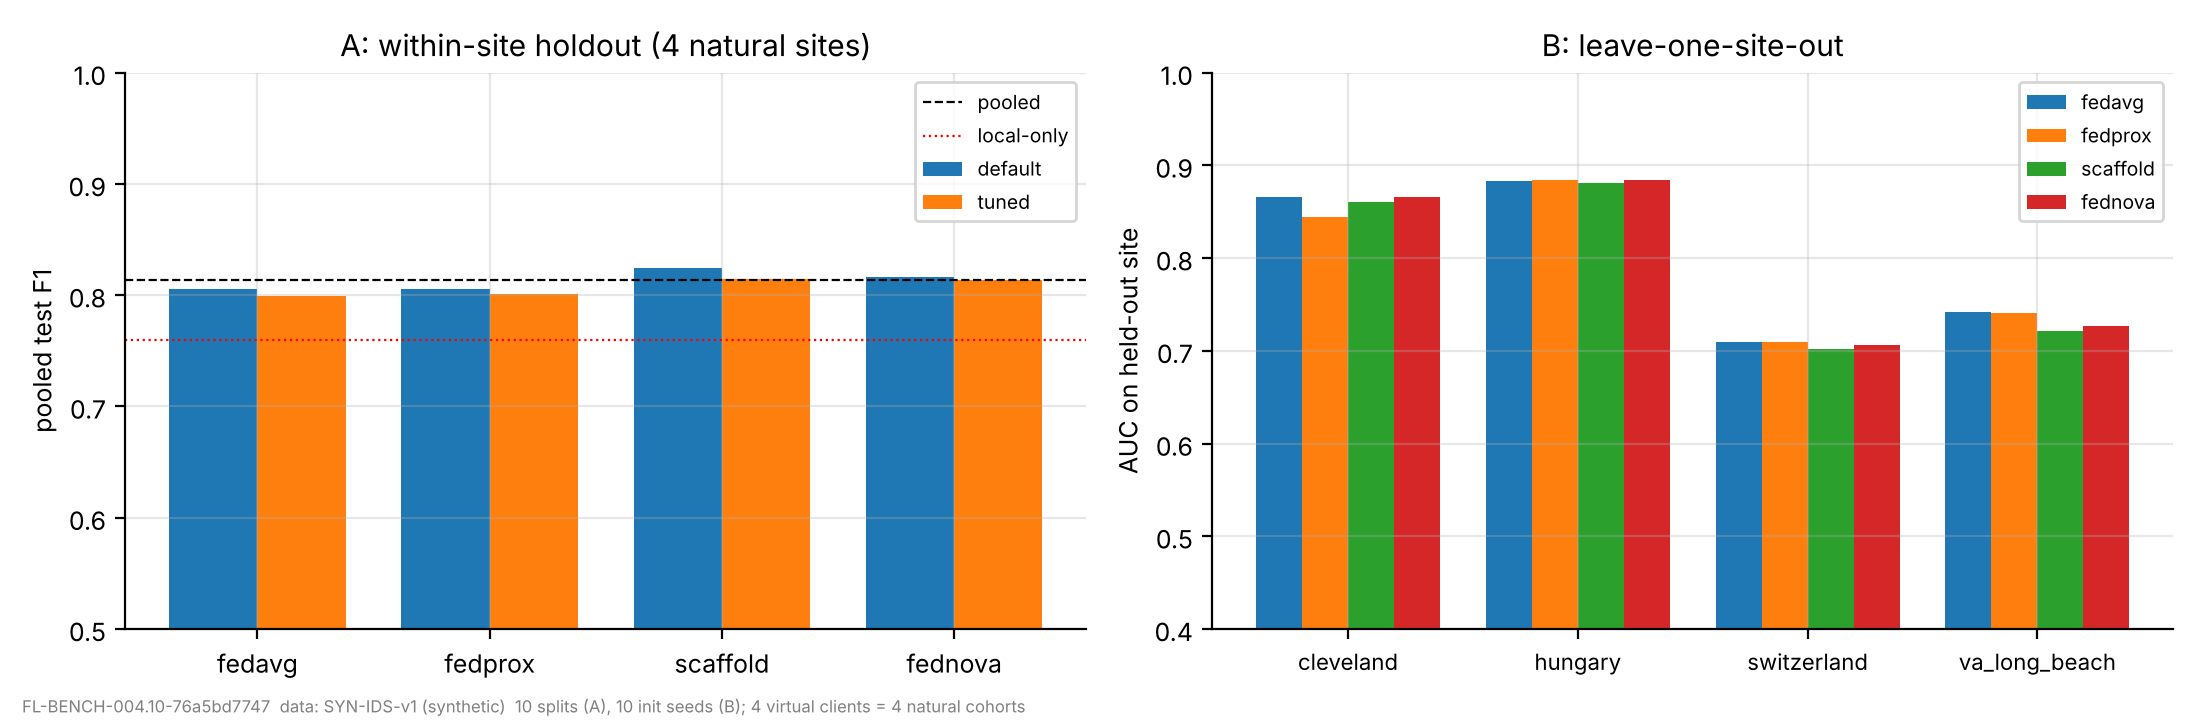

In [10]:
show_fig('task_4_10_natural_sites.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

Switzerland has 8 negatives, so F1/accuracy there are inflated; AUC and balanced accuracy are the primary metrics for site-level statements.

In [11]:
show_csv('task_4_10_A_site_summary.csv', 20); show_csv('task_4_10_secagg_equivalence.csv')

,algo,site,n,acc,acc_ci,f1,f1_ci,auc,auc_ci
0,fedavg,cleveland,10,0.7725,"[0.7404, 0.8046]",0.7583,"[0.7297, 0.7868]",0.8600,"[0.8345, 0.8855]"
1,fedavg,hungary,10,0.8079,"[0.7856, 0.8301]",0.7393,"[0.7120, 0.7666]",0.8728,"[0.8480, 0.8976]"
2,fedavg,switzerland,10,0.7649,"[0.6966, 0.8331]",0.8588,"[0.8134, 0.9041]",0.7229,"[0.5550, 0.8907]"
3,fedavg,va_long_beach,10,0.7467,"[0.7165, 0.7768]",0.8381,"[0.8186, 0.8576]",0.6964,"[0.6436, 0.7493]"
4,fedprox,cleveland,10,0.7714,"[0.7472, 0.7957]",0.7577,"[0.7327, 0.7827]",0.8629,"[0.8388, 0.8870]"
5,fedprox,hungary,10,0.8034,"[0.7740, 0.8328]",0.7361,"[0.7017, 0.7704]",0.8718,"[0.8459, 0.8976]"
6,fedprox,switzerland,10,0.7622,"[0.7054, 0.8189]",0.8587,"[0.8218, 0.8955]",0.6943,"[0.5151, 0.8735]"
7,fedprox,va_long_beach,10,0.7583,"[0.7236, 0.7931]",0.8460,"[0.8236, 0.8685]",0.7007,"[0.6471, 0.7544]"
8,scaffold,cleveland,10,0.7868,"[0.7562, 0.8174]",0.7737,"[0.7398, 0.8075]",0.8554,"[0.8334, 0.8774]"
9,scaffold,hungary,10,0.8034,"[0.7771, 0.8297]",0.7498,"[0.7239, 0.7756]",0.8650,"[0.8398, 0.8903]"


,split,max_abs_param_diff_secagg_vs_plain,f1_plain,f1_secagg
0,0,0.0,0.8232,0.8232
1,1,0.0,0.7855,0.7855
2,2,0.0,0.7907,0.7907


## 16. Limitations
- Four 1980s research cohorts, n=920; not a live hospital federation.
- Pooled imputation/standardisation is a centralised preprocessing step.
- Mirror licence not verified; files are not redistributed.
- Protocol B p-values (if any) reflect training noise only.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
See results_and_discussion.md.

**Jira acceptance:** see `docs/fl_bench_004/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`uci_heart`, `kairouz2021`, `hsu2019`, `li2021niid`, `mcmahan2017` — details in `docs/fl_bench_004/references.md`.